In [1]:
import torch
import geospaNN
import numpy as np
import pandas as pd
import random
import matplotlib
import matplotlib.pyplot as plt

R callback write-console: Loading required package: BRISC
  
R callback write-console: Loading required package: RANN
  
R callback write-console: Loading required package: parallel
  
R callback write-console: Loading required package: rdist
  
R callback write-console: Loading required package: matrixStats
  
R callback write-console: Loading required package: pbapply
  
R callback write-console: The ordering of inputs x (covariates) and y (response) in BRISC_estimation has been changed BRISC 1.0.0 onwards.
  Please check the new documentation with ?BRISC_estimation.
  


R package: BRISC installed


/opt/anaconda3/envs/geomed2026/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def f5(X): return (10 * np.sin(np.pi * X[:, 0] * X[:, 1]) + 20 * (X[:, 2] - 0.5) ** 2 + 10 * X[:, 3] + 5 * X[:, 4]) / 6
p = 5;
funXY = f5

n = 1000
nn = 20
b = 10

sigma = 1
phi = 1
Lambda = 0.01
theta = torch.tensor([sigma, phi / np.sqrt(2), Lambda])

In [3]:
# Simulate data
torch.manual_seed(2026) #2024
X, Y, coord, cov, corerr = geospaNN.Simulation(n, p, nn, funXY, theta, range=[0, b])

# Preprocess data
random.seed(2024)
X, Y, coord, _ = geospaNN.spatial_order(X, Y, coord, method='max-min')
data = geospaNN.make_graph(X, Y, coord, nn)

torch.manual_seed(2026) #2024
np.random.seed(0)
data_train, data_val, data_test = geospaNN.split_data(X, Y, coord, neighbor_size=nn,
                                                      test_proportion=0.2)

/var/folders/_w/4z9wsc814_v5pp5ywhnpmlw80000gn/T/ipykernel_93274/4130038091.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  def f5(X): return (10 * np.sin(np.pi * X[:, 0] * X[:, 1]) + 20 * (X[:, 2] - 0.5) ** 2 + 10 * X[:, 3] + 5 * X[:, 4]) / 6


In [4]:
data_train.x

tensor([[0.4108, 0.4185, 0.3626, 0.6323, 0.5652],
        [0.6141, 0.7502, 0.2136, 0.7234, 0.4050],
        [0.2598, 0.0383, 0.4369, 0.5678, 0.3807],
        ...,
        [0.4963, 0.4939, 0.0505, 0.4218, 0.3140],
        [0.1186, 0.4668, 0.0989, 0.0963, 0.8975],
        [0.2478, 0.8180, 0.4934, 0.8952, 0.7605]])

/opt/anaconda3/envs/geomed2026/lib/python3.10/site-packages/geospaNN/visualize.py:147: UserWarning: length of names does not match columns of X, replace by variable index
  warnings.warn("length of names does not match columns of X, replace by variable index")
/var/folders/_w/4z9wsc814_v5pp5ywhnpmlw80000gn/T/ipykernel_93274/4130038091.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  def f5(X): return (10 * np.sin(np.pi * X[:, 0] * X[:, 1]) + 20 * (X[:, 2] - 0.5) ** 2 + 10 * X[:, 3] + 5 * X[:, 4]) / 6
/var/folders/_w/4z9wsc814_v5pp5ywhnpmlw80000gn/T/ipykernel_93274/4130038091.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  def f5(X): return (10 * np.sin(np.pi * X[:, 0] * X[:, 1]) + 20 * (X[:, 2] - 0.5) ** 2 + 10 * X[:, 3] + 5 * X[:, 4]) / 6
/var/folders/_w/4z9wsc814_v5pp5ywhnpmlw80000gn/T/ipykernel_

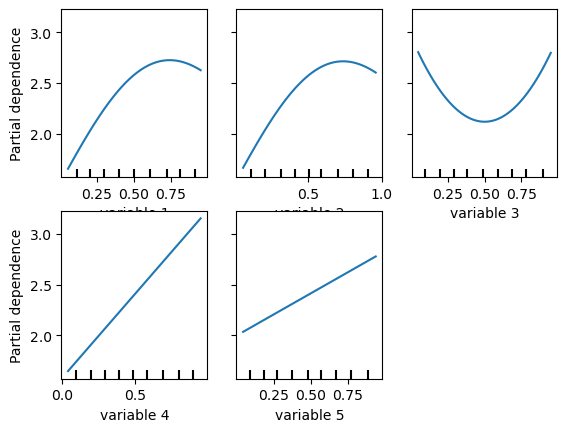

In [5]:
PDP_truth = geospaNN.visualize.plot_PDP(f5, X, names = ["PDP"], save = False)

In [6]:
torch.manual_seed(2024)
mlp_nn = torch.nn.Sequential(
    torch.nn.Linear(p, 50),
    torch.nn.ReLU(),
    torch.nn.Linear(50, 20),
    torch.nn.ReLU(),
    torch.nn.Linear(20, 1)
)
trainer_nn = geospaNN.nn_train(mlp_nn, lr=0.05, min_delta=0.001)
training_log = trainer_nn.train(data_train, data_val, data_test, seed = 2)
theta0 = geospaNN.theta_update(mlp_nn(data_train.x).squeeze() - data_train.y, data_train.pos, neighbor_size=20)

INFO: Early stopping
End at epoch34
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[0.79321335 0.82867213 0.16133549]


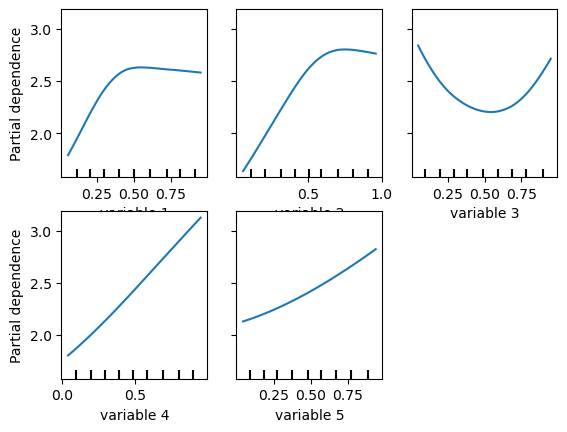

In [7]:
PDP_NN = geospaNN.visualize.plot_PDP(mlp_nn, X, names = ["PDP"], save = False)

In [8]:
torch.manual_seed(2024)
mlp_nngls = torch.nn.Sequential(
    torch.nn.Linear(p, 50),
    torch.nn.ReLU(),
    torch.nn.Linear(50, 20),
    torch.nn.ReLU(),
    torch.nn.Linear(20, 1)
)
nngls = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_nngls, theta=torch.tensor(theta0))
trainer_nngls = geospaNN.nngls_train(nngls, lr=0.01, min_delta=0.001)
training_log = trainer_nngls.train(data_train, data_val, data_test,
                                   Update_init=20, Update_step=10, seed = 2)

---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[0.93526292 0.84338924 0.05998453]
to
[0.93526292 0.84338924 0.05998453]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[0.91355895 0.80862905 0.03795783]
to
[0.91355895 0.80862905 0.03795783]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[0.89799551 0.86126036 0.01349073]
to
[0.89799551 0.86126036 0.01349073]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[0.91551013 0.82153957 0.00967928]
to
[0.91551013 0.82153957 0.00967928]
INFO: Early stopping
End at epoch56


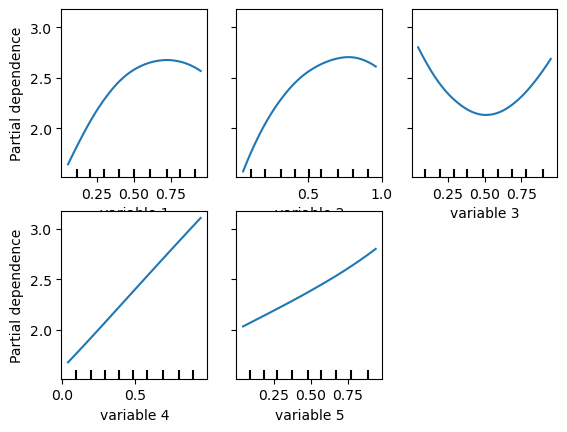

In [9]:
PDP_NNGLS = geospaNN.visualize.plot_PDP(mlp_nngls, X, names = ["PDP"], save = False)

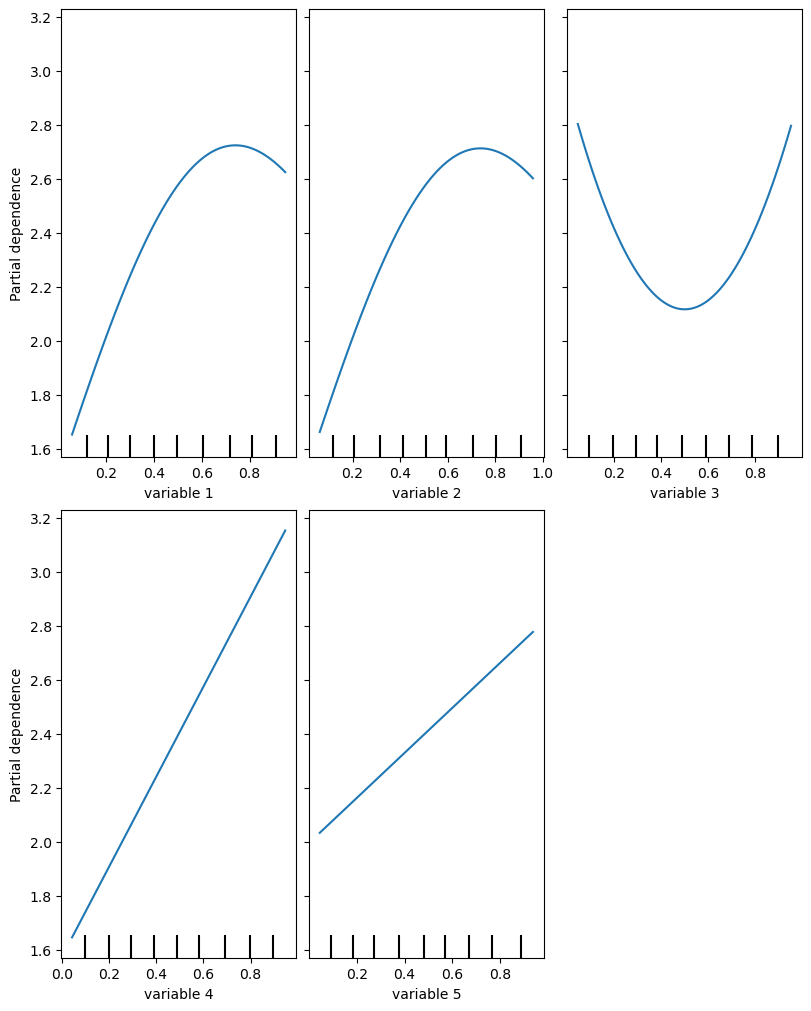

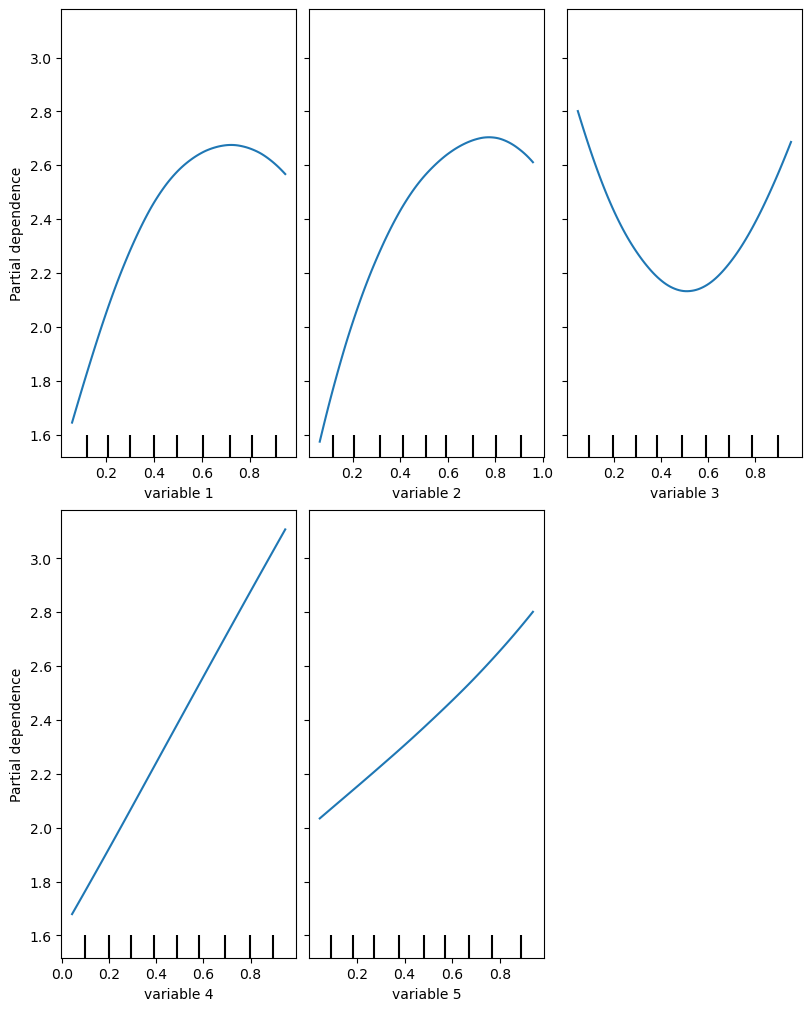

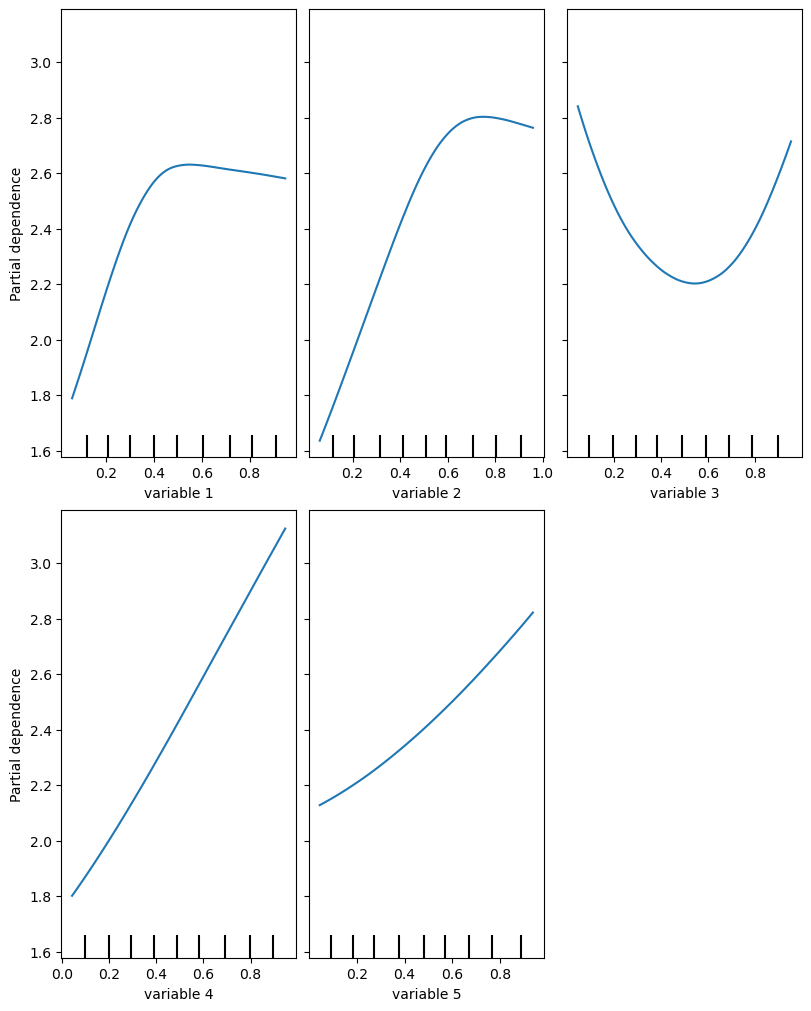

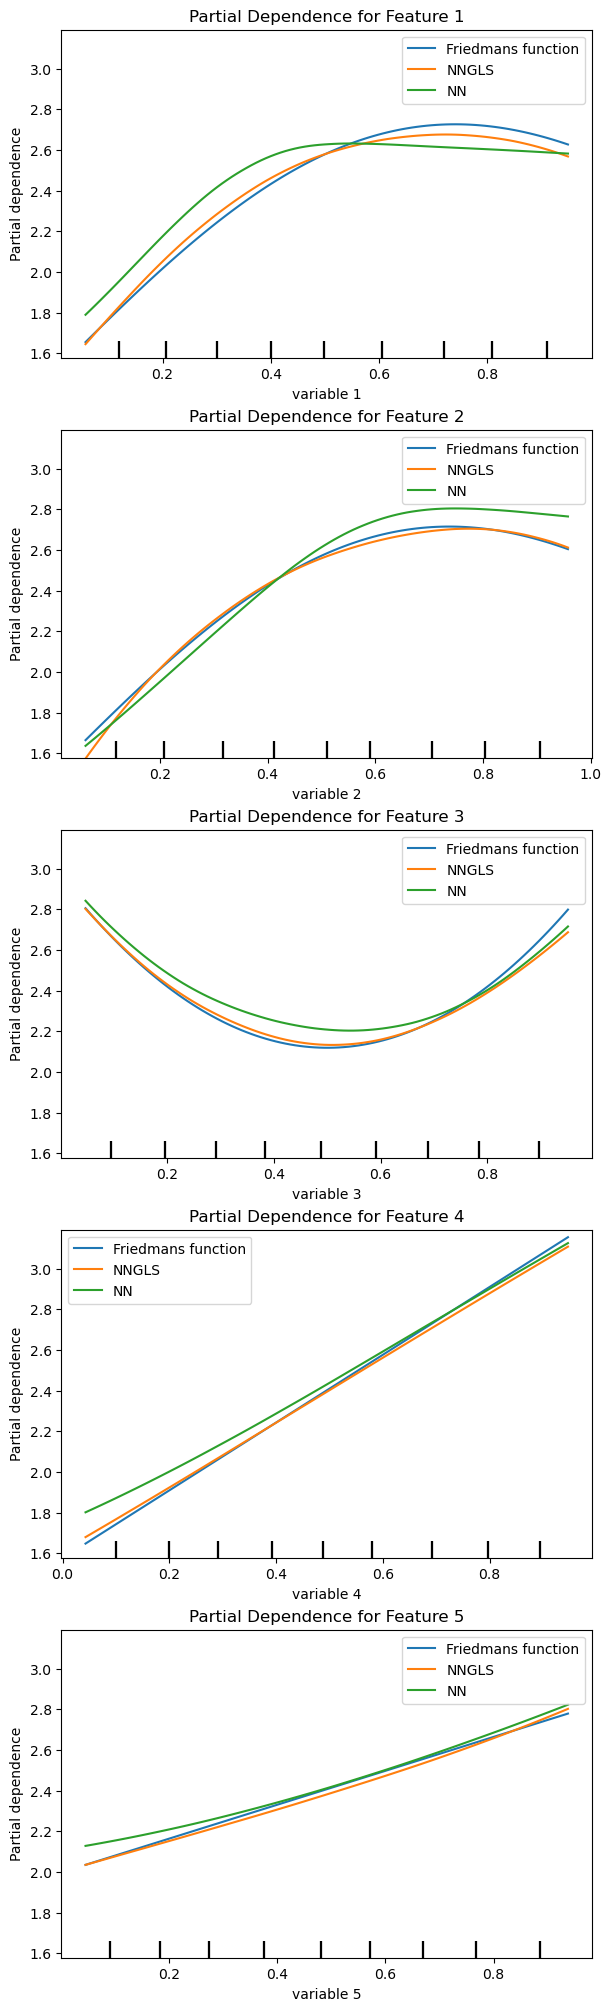

In [11]:
import matplotlib as mpl

mpl.rcParams['figure.figsize'] = (8, 10)
mpl.rcParams['figure.constrained_layout.use'] = True

geospaNN.visualize.plot_PDP_list(
    [funXY, mlp_nngls, mlp_nn],
    ['Friedmans function', 'NNGLS', 'NN'],
    X,
    save=False
)